# Practical 6, Part II: Kinetic Monte Carlo Simulation of Diffusion

**Materials Simulation Practical 6, implementation tasks** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Frank Wendler
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

The derivation of the rates, the time mapping for a time-dependent temperature, the coarse-graining
rules and the kick-out model are in Part I (`report/main.pdf`). This notebook implements the three
problems of the script with an own KMC code; the inner loops are compiled with `numba`.

| Problem | Content | Section |
|---|---|---|
| 2.1 | atomistic KMC of Al in a Cu/Cu–10 % Al sandwich; isothermal checks at 500 K and 600 K; heating to 873 K in 1 s | [2](#2) |
| 2.2 | coarse-grained KMC, $2\times0.1$ mm, heating in $10^6$ s; blocked-site treatment | [3](#3) |
| 2.3 | Au in Si by the kick-out mechanism, 1 mm wafer, 1050 °C, 1000 s | [4](#4) |

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erf
from scipy.integrate import quad, solve_ivp
from numba import njit

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})

R_GAS = 8.314462618
D0, Q = 1.49e-7, 137.1e3          # Al in Cu: D = D0 exp(-Q/RT)  [m^2/s]
B_CU = 2.54e-10                   # nearest-neighbour spacing of Cu [m]


def D_al(T):
    return D0 * np.exp(-Q / (R_GAS * T))


for T in (300, 500, 600, 873):
    print(f"T = {T:4d} K: D = {D_al(T):.3e} m^2/s, jump rate per direction Gamma = D/b^2 = "
          f"{D_al(T)/B_CU**2:.3e} 1/s")

T =  300 K: D = 2.006e-31 m^2/s, jump rate per direction Gamma = D/b^2 = 3.110e-12 1/s
T =  500 K: D = 7.091e-22 m^2/s, jump rate per direction Gamma = D/b^2 = 1.099e-02 1/s
T =  600 K: D = 1.729e-19 m^2/s, jump rate per direction Gamma = D/b^2 = 2.680e+00 1/s
T =  873 K: D = 9.336e-16 m^2/s, jump rate per direction Gamma = D/b^2 = 1.447e+04 1/s


<a id="1"></a>
## 1 The KMC kernels

* **Lattice KMC (Problem 2.1).** All Al atoms have the same jump rate $\Gamma(t) = D(T(t))/b^2$ per
  direction on the 2D square lattice (for which $D = \Gamma b^2$). The script's selection by
  cumulative probabilities then reduces to picking an atom and a direction uniformly; a jump onto an
  occupied site or out of the film is rejected as a null event, which is exactly equivalent to
  excluding it from the event list. Because every rate is proportional to $\Gamma(t)$, the evolution is
  a function of the reduced time $\tau = \int_0^t\Gamma\,\mathrm dt'$ only: each attempt advances $\tau$
  by $-\ln R_2/(4N)$, and the temperature history enters solely through the map $\tau \leftrightarrow t$.
* **Cell KMC (Problem 2.2).** Rejection-free (BKL) selection among the $2m$ hops between neighbouring
  cells with rate $(D/L^2)\,n_i\,(1 - n_j/n_{\max})$, again in reduced time $\int D\,\mathrm dt/L^2$.
* **Kick-out KMC (Problem 2.3).** BKL with per-cell rate sums updated incrementally.

In [2]:
# ---------------------------------------------------------------- Task 1: atomistic lattice KMC
@njit
def lattice_kmc(occ, pos, tau_targets, seed):
    """Al on a 2D square lattice (x: film normal, reflecting; y: periodic).

    Every Al atom attempts each of its 4 jumps with the same rate Gamma(t); jumps onto an occupied
    site or out of the film are rejected (null events). Time is the reduced time tau = int Gamma dt,
    so each attempt advances tau by Exp(1)/(4 N). Returns the x-profile (atoms per column) at each
    target tau and the number of accepted jumps.
    """
    np.random.seed(seed)
    nx, ny = occ.shape
    n = pos.shape[0]
    rate_tot = 4.0 * n
    out = np.zeros((tau_targets.size, nx))
    tau = 0.0
    k = 0
    accepted = 0
    dxs = np.array([1, -1, 0, 0])
    dys = np.array([0, 0, 1, -1])
    while k < tau_targets.size:
        tau += -np.log(np.random.random()) / rate_tot
        while k < tau_targets.size and tau >= tau_targets[k]:
            for a in range(n):
                out[k, pos[a, 0]] += 1.0
            k += 1
        a = np.random.randint(n)
        d = np.random.randint(4)
        x = pos[a, 0] + dxs[d]
        if x < 0 or x >= nx:
            continue
        y = (pos[a, 1] + dys[d]) % ny
        if occ[x, y]:
            continue
        occ[pos[a, 0], pos[a, 1]] = False
        occ[x, y] = True
        pos[a, 0] = x
        pos[a, 1] = y
        accepted += 1
    return out, accepted


# ---------------------------------------------------------------- Task 2: coarse-grained cells
@njit
def cell_kmc(nc, nmax, tau_targets, seed, blocking):
    """Diffusors in 1D cells; hop i -> i+-1 with rate (D/L^2) n_i (1 - n_j/nmax).

    All rates are proportional to D(t), so the simulation runs in tau = int D dt / L^2 and is
    rejection-free (BKL). Reflecting outer boundaries.
    """
    np.random.seed(seed)
    m = nc.size
    out = np.zeros((tau_targets.size, m))
    tau = 0.0
    k = 0
    while k < tau_targets.size:
        # rates of the 2m possible events (right hop, left hop per cell)
        tot = 0.0
        for i in range(m):
            if i + 1 < m:
                tot += nc[i] * ((1.0 - nc[i + 1] / nmax) if blocking else 1.0)
            if i > 0:
                tot += nc[i] * ((1.0 - nc[i - 1] / nmax) if blocking else 1.0)
        tau += -np.log(np.random.random()) / tot
        while k < tau_targets.size and tau >= tau_targets[k]:
            out[k, :] = nc
            k += 1
        r = np.random.random() * tot
        acc = 0.0
        for i in range(m):
            if i + 1 < m:
                acc += nc[i] * ((1.0 - nc[i + 1] / nmax) if blocking else 1.0)
                if acc >= r:
                    nc[i] -= 1; nc[i + 1] += 1
                    break
            if i > 0:
                acc += nc[i] * ((1.0 - nc[i - 1] / nmax) if blocking else 1.0)
                if acc >= r:
                    nc[i] -= 1; nc[i - 1] += 1
                    break
    return out


# ---------------------------------------------------------------- Task 3: kick-out
@njit
def kickout_kmc(m, hop, kf, kr_eff, src_rate, t_targets, seed):
    """Coarse-grained KMC of Au_i + Si <-> Au_s + I in m cells.

    Events per cell i:
      0 Au_i hop right   hop*ni      (out of the right surface: reflected, i.e. forbidden)
      1 Au_i hop left    hop*ni      (out of the left surface: the atom returns to the Au layer)
      2 I hop right      hop*nI      (out of the right surface: annihilated)
      3 I hop left       hop*nI      (out of the left surface: annihilated)
      4 kick-out         kf*ni               Au_i -> Au_s + I
      5 reverse          kr_eff*ns*nI        Au_s + I -> Au_i
    plus the injection of Au_i from the gold layer into cell 0 at src_rate.
    Rates are kept per cell and updated incrementally; the event is found by a linear scan.
    """
    np.random.seed(seed)
    ni = np.zeros(m); ns = np.zeros(m); nI = np.zeros(m)
    cell_rate = np.zeros(m)
    out = np.zeros((t_targets.size, 3, m))
    t = 0.0
    k = 0
    nev = 0

    def rates(i):
        r_i = hop * ni[i] * ((1.0 if i + 1 < m else 0.0) + 1.0)
        r_I = 2.0 * hop * nI[i]
        return r_i + r_I + kf * ni[i] + kr_eff * ns[i] * nI[i]

    for i in range(m):
        cell_rate[i] = rates(i)
    tot = cell_rate.sum() + src_rate
    while k < t_targets.size:
        t += -np.log(np.random.random()) / tot
        while k < t_targets.size and t >= t_targets[k]:
            out[k, 0, :] = ni; out[k, 1, :] = ns; out[k, 2, :] = nI
            k += 1
        r = np.random.random() * tot
        nev += 1
        if r < src_rate:
            ni[0] += 1.0
            tot -= cell_rate[0]; cell_rate[0] = rates(0); tot += cell_rate[0]
            continue
        r -= src_rate
        i = 0
        while i < m - 1 and r >= cell_rate[i]:
            r -= cell_rate[i]
            i += 1
        right = hop * ni[i] if i + 1 < m else 0.0
        left = hop * ni[i]
        Ih = hop * nI[i]
        fw = kf * ni[i]
        j = -1
        if r < right:
            ni[i] -= 1; ni[i + 1] += 1; j = i + 1
        elif r < right + left:
            ni[i] -= 1
            if i > 0:
                ni[i - 1] += 1; j = i - 1
        elif r < right + left + Ih:
            nI[i] -= 1
            if i + 1 < m:
                nI[i + 1] += 1; j = i + 1
        elif r < right + left + 2 * Ih:
            nI[i] -= 1
            if i > 0:
                nI[i - 1] += 1; j = i - 1
        elif r < right + left + 2 * Ih + fw:
            ni[i] -= 1; ns[i] += 1; nI[i] += 1
        else:
            ns[i] -= 1; nI[i] -= 1; ni[i] += 1
        tot -= cell_rate[i]; cell_rate[i] = rates(i); tot += cell_rate[i]
        if j >= 0:
            tot -= cell_rate[j]; cell_rate[j] = rates(j); tot += cell_rate[j]
        if nev % 1000000 == 0:                  # guard against round-off drift of tot
            tot = cell_rate.sum() + src_rate
    return out, nev

<a id="2"></a>
## 2 Atomistic KMC: Al in a Cu thin-film sandwich (Problem 2.1)

**Geometry.** Two films of 100 nm each, i.e. $394$ lattice planes of spacing $b = 2.54$ Å, along $x$
(the film normal); the directions parallel to the film are represented by a periodic $y$ direction of
100 sites, which is all the 2D simplification of the hint requires because the problem is homogeneous
in the film plane. The outer surfaces are reflecting. The right film is Cu–10 % Al, with Al placed at
random on 10 % of its sites. Profiles are averaged over the $y$ direction, over 4 independent runs, and
binned into 5 nm slabs.

In [3]:
NX_HALF, NY = 394, 100
NX = 2 * NX_HALF
X = (np.arange(NX) + 0.5) * B_CU
X0 = NX_HALF * B_CU
C0 = 0.10


def initial_film(seed):
    rng = np.random.default_rng(seed)
    occ = np.zeros((NX, NY), dtype=np.bool_)
    sites = np.arange(NX_HALF * NY)
    pick = rng.choice(sites, size=int(C0 * sites.size), replace=False)
    pos = np.stack([NX_HALF + pick // NY, pick % NY], axis=1).astype(np.int64)
    occ[pos[:, 0], pos[:, 1]] = True
    return occ, pos


def run_lattice(tau_targets, n_runs=4):
    profiles, accepted = [], 0
    for s in range(n_runs):
        occ, pos = initial_film(s)
        prof, acc = lattice_kmc(occ, pos, np.asarray(tau_targets, float), 100 + s)
        profiles.append(prof / NY)
        accepted += acc
    return np.mean(profiles, axis=0), accepted


def binned(c, width_nm=5.0):
    k = int(round(width_nm * 1e-9 / B_CU))
    n = (len(c) // k) * k
    return X[:n].reshape(-1, k).mean(axis=1), c[:n].reshape(-1, k).mean(axis=1)


def erf_profile(x, Dt):
    return C0 / 2 * (1 + erf((x - X0) / (2 * np.sqrt(Dt))))


_, pos0 = initial_film(0)
print(f"{NX} x {NY} lattice, {len(pos0)} Al atoms per run")

788 x 100 lattice, 3940 Al atoms per run


### 2.1 Verification: isothermal annealing at 500 K and 600 K

For constant $T$ the solution of the diffusion equation for two semi-infinite regions is the
error-function profile $c = \tfrac{c_0}{2}[1 + \mathrm{erf}((x-x_0)/2\sqrt{Dt})]$. We anneal for times
that give $\sqrt{Dt} = 5$ and 10 nm at each temperature.

T = 500 K: anneal times 3.53e+04 s and 1.41e+05 s (2.21e+07 accepted jumps per run, 1.9 s)
   t =  3.53e+04 s: rms deviation from erf = 0.0024 (c0 = 0.1)
   t =  1.41e+05 s: rms deviation from erf = 0.0028 (c0 = 0.1)


T = 600 K: anneal times 145 s and 578 s (2.21e+07 accepted jumps per run, 1.5 s)
   t =       145 s: rms deviation from erf = 0.0024 (c0 = 0.1)
   t =       578 s: rms deviation from erf = 0.0028 (c0 = 0.1)


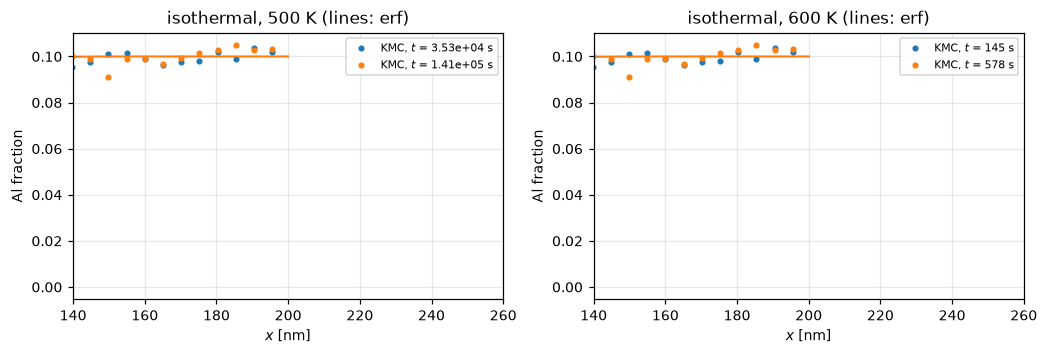

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.3))
for a, T in zip(ax, (500, 600)):
    D = D_al(T)
    times = np.array([(5e-9) ** 2, (10e-9) ** 2]) / D           # sqrt(Dt) = 5 and 10 nm
    t0 = time.time()
    prof, acc = run_lattice(D * times / B_CU ** 2)
    print(f"T = {T} K: anneal times {times[0]:.3g} s and {times[1]:.3g} s "
          f"({acc/4:.2e} accepted jumps per run, {time.time()-t0:.1f} s)")
    for p, t, col in zip(prof, times, ("C0", "C1")):
        xb, cb = binned(p)
        a.plot(xb * 1e9, cb, "o", ms=3, color=col, label=f"KMC, $t$ = {t:.3g} s")
        a.plot(X * 1e9, erf_profile(X, D * t), "-", lw=1.0, color=col)
        rms = np.sqrt(np.mean((cb - erf_profile(xb, D * t)) ** 2))
        print(f"   t = {t:9.3g} s: rms deviation from erf = {rms:.4f} (c0 = {C0})")
    a.set(xlabel="$x$ [nm]", ylabel="Al fraction", title=f"isothermal, {T} K (lines: erf)",
          xlim=(140, 260))
    a.legend(fontsize=7)
plt.show()

At both temperatures the KMC profiles fall on the error-function solution to within the statistical
noise of the 5 nm slabs ($\approx 0.003$), which verifies the rate $\Gamma = D/b^2$ and the time
mapping. Note that the *same* reduced time gives the *same* profile: 500 K for $10^5$ s and 600 K for a
few hundred seconds are statistically identical simulations. The atomic blocking does not alter the
profile because, for this exclusion process, the expected occupation obeys the discrete diffusion
equation exactly (Part I); it only slows down the individual (tracer) atoms.

### 2.2 Heating from 300 K to 873 K in 1 s

With $T(t) = 300\,\mathrm K + 573\,\mathrm K\cdot t/\mathrm s$, the reduced time is
$\tau(t) = b^{-2}\int_0^t D(T(t'))\,\mathrm dt'$, and the erf solution remains valid with $Dt$ replaced
by $\int_0^t D\,\mathrm dt'$, since a time-dependent but spatially uniform $D$ only rescales time.

t = 0.50 s (T = 586.5 K): int D dt = 3.128e-21 m^2, sqrt =   0.06 nm, jumps per atom =      0.2
t = 0.80 s (T = 758.4 K): int D dt = 3.008e-18 m^2, sqrt =   1.73 nm, jumps per atom =    186.5
t = 0.90 s (T = 815.7 K): int D dt = 1.593e-17 m^2, sqrt =   3.99 nm, jumps per atom =    987.9
t = 0.95 s (T = 844.4 K): int D dt = 3.380e-17 m^2, sqrt =   5.81 nm, jumps per atom =   2095.6
t = 1.00 s (T = 873.0 K): int D dt = 6.839e-17 m^2, sqrt =   8.27 nm, jumps per atom =   4240.0


1.51e+07 accepted jumps per run, 1.0 s


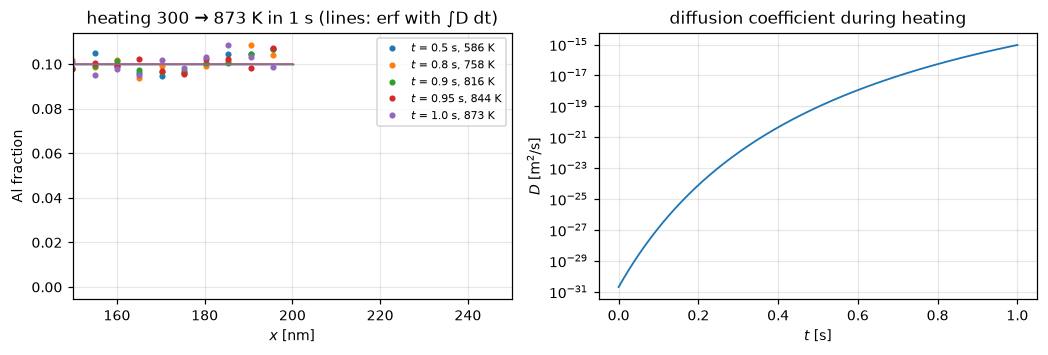

only 23 % of the total int D dt is accumulated before t = 0.9 s: almost all interdiffusion happens in the last 100 ms, above about 816 K


In [5]:
T_of_t = lambda t: 300.0 + 573.0 * t
Dint = lambda t: quad(lambda s: D_al(T_of_t(s)), 0.0, t, limit=200)[0]
t_snap = np.array([0.5, 0.8, 0.9, 0.95, 1.0])
Dt_snap = np.array([Dint(t) for t in t_snap])
for t, Dt in zip(t_snap, Dt_snap):
    print(f"t = {t:4.2f} s (T = {T_of_t(t):5.1f} K): int D dt = {Dt:.3e} m^2, "
          f"sqrt = {np.sqrt(Dt)*1e9:6.2f} nm, jumps per atom = {4*Dt/B_CU**2:8.1f}")

t0 = time.time()
prof_ramp, acc = run_lattice(Dt_snap / B_CU ** 2)
print(f"{acc/4:.2e} accepted jumps per run, {time.time()-t0:.1f} s")
heat_profiles = dict(zip(t_snap, prof_ramp))

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.3))
for t, Dt, p in zip(t_snap, Dt_snap, prof_ramp):
    xb, cb = binned(p)
    l, = ax[0].plot(xb * 1e9, cb, "o", ms=3, label=f"$t$ = {t} s, {T_of_t(t):.0f} K")
    ax[0].plot(X * 1e9, erf_profile(X, Dt), "-", lw=0.9, color=l.get_color())
ax[0].set(xlabel="$x$ [nm]", ylabel="Al fraction", xlim=(150, 250),
          title="heating 300 → 873 K in 1 s (lines: erf with ∫D dt)")
ax[0].legend(fontsize=7)
tt = np.linspace(0, 1, 400)
ax[1].semilogy(tt, [D_al(T_of_t(s)) for s in tt], lw=1.2)
ax[1].set(xlabel="$t$ [s]", ylabel="$D$ [m$^2$/s]", title="diffusion coefficient during heating")
plt.show()
frac = Dint(0.9) / Dint(1.0)
print(f"only {100*frac:.0f} % of the total int D dt is accumulated before t = 0.9 s: almost all "
      f"interdiffusion happens in the last 100 ms, above about {T_of_t(0.9):.0f} K")

<a id="3"></a>
## 3 Coarse-grained KMC (Problem 2.2)

Two layers of 0.1 mm, heating from 300 K to 873 K over $10^6$ s. The diffusors now hop between cells
of size $L = 1$ µm. For the coarse-grained random walk to reproduce the macroscopic diffusion
coefficient the hop rate in the dilute limit must be $D/L^2$ per direction; the blocked-site effect is
the probability $1 - n_j/n_{\max}$ that the target site in the neighbouring cell is free, with
$n_{\max}$ the number of lattice sites per cell. We use the same number of diffusors as in Problem 2.1
(3940), so $n_{\max} = 394$ and each cell of the Al-rich layer starts with 39 or 40 diffusors
(10 %).

t = 8.00e+05 s (T = 758 K): sqrt(int D dt) =   1.73 um
t = 9.00e+05 s (T = 816 K): sqrt(int D dt) =   3.99 um
t = 9.50e+05 s (T = 844 K): sqrt(int D dt) =   5.81 um
t = 1.00e+06 s (T = 873 K): sqrt(int D dt) =   8.27 um


coarse-grained runs: 4.5 s
t = 8.00e+05 s: rms(blocking - erf) = 0.0035, rms(no blocking - erf) = 0.0040
t = 9.00e+05 s: rms(blocking - erf) = 0.0039, rms(no blocking - erf) = 0.0039
t = 9.50e+05 s: rms(blocking - erf) = 0.0042, rms(no blocking - erf) = 0.0043
t = 1.00e+06 s: rms(blocking - erf) = 0.0038, rms(no blocking - erf) = 0.0033


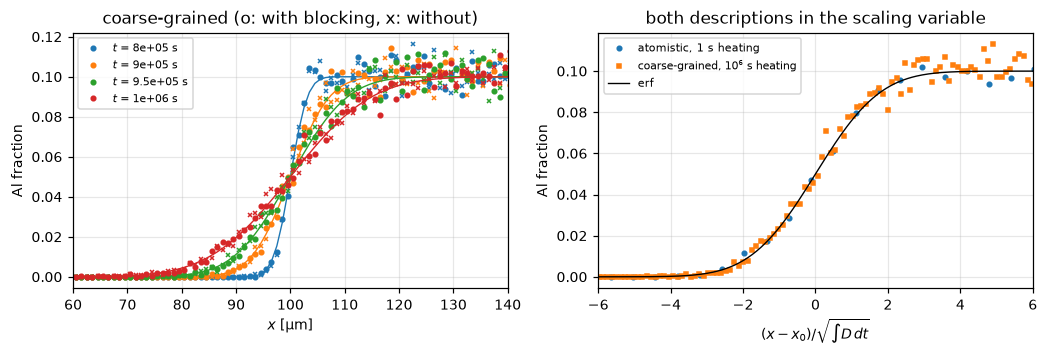

In [6]:
L_CELL = 1e-6
M_CELLS = 200
N_DIFF = 3940
N_MAX = 394.0
XC = (np.arange(M_CELLS) + 0.5) * L_CELL
XC0 = 100 * L_CELL

T2 = lambda t: 300.0 + 573.0 * t / 1e6
Dint2 = lambda t: quad(lambda s: D_al(T2(s)), 0.0, t, limit=400, points=[0.8e6, 0.9e6])[0]
t2_snap = np.array([0.8e6, 0.9e6, 0.95e6, 1.0e6])
Dt2 = np.array([Dint2(t) for t in t2_snap])
for t, Dt in zip(t2_snap, Dt2):
    print(f"t = {t:.2e} s (T = {T2(t):.0f} K): sqrt(int D dt) = {np.sqrt(Dt)*1e6:6.2f} um")


def initial_cells():
    nc = np.zeros(M_CELLS)
    per = np.full(100, N_DIFF // 100, float)
    per[: N_DIFF - per.sum().astype(int)] += 1
    nc[100:] = per
    return nc


def run_cells(blocking, n_runs=8):
    out = []
    for s in range(n_runs):
        out.append(cell_kmc(initial_cells(), N_MAX, Dt2 / L_CELL ** 2, 200 + s, blocking))
    return np.mean(out, axis=0) / N_MAX


t0 = time.time()
cg_block = run_cells(True)
cg_free = run_cells(False)
print(f"coarse-grained runs: {time.time()-t0:.1f} s")
erf2 = lambda x, Dt: C0 / 2 * (1 + erf((x - XC0) / (2 * np.sqrt(Dt))))

fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.3))
for k, (t, Dt) in enumerate(zip(t2_snap, Dt2)):
    l, = ax[0].plot(XC * 1e6, cg_block[k], "o", ms=3, label=f"$t$ = {t:.2g} s")
    ax[0].plot(XC * 1e6, cg_free[k], "x", ms=3, color=l.get_color())
    ax[0].plot(XC * 1e6, erf2(XC, Dt), "-", lw=0.9, color=l.get_color())
    print(f"t = {t:.2e} s: rms(blocking - erf) = {np.sqrt(np.mean((cg_block[k]-erf2(XC,Dt))**2)):.4f}, "
          f"rms(no blocking - erf) = {np.sqrt(np.mean((cg_free[k]-erf2(XC,Dt))**2)):.4f}")
ax[0].set(xlabel="$x$ [µm]", ylabel="Al fraction", xlim=(60, 140),
          title="coarse-grained (o: with blocking, x: without)")
ax[0].legend(fontsize=7)

# comparison with the atomistic result in the scaling variable (x - x0)/sqrt(int D dt)
xa, ca = binned(heat_profiles[1.0])
ax[1].plot((xa - X0) / np.sqrt(Dt_snap[-1]), ca, "o", ms=3, label="atomistic, 1 s heating")
ax[1].plot((XC - XC0) / np.sqrt(Dt2[-1]), cg_block[-1], "s", ms=3, label=r"coarse-grained, $10^6$ s heating")
u = np.linspace(-6, 6, 300)
ax[1].plot(u, C0 / 2 * (1 + erf(u / 2)), "k-", lw=0.9, label="erf")
ax[1].set(xlabel=r"$(x - x_0)/\sqrt{\int D\,dt}$", ylabel="Al fraction", xlim=(-6, 6),
          title="both descriptions in the scaling variable")
ax[1].legend(fontsize=7)
plt.show()

Both coarse-grained variants reproduce the erf solution with $\int D\,\mathrm dt$, and in the scaling
variable $(x-x_0)/\sqrt{\int D\,\mathrm dt}$ the atomistic profile (1 s heating, nanometres) and the
coarse-grained profile ($10^6$ s heating, micrometres) collapse onto the same curve, as they must,
because both are realizations of the same diffusion equation. The coarse-grained run needs about
$2\int D\,\mathrm dt/L^2 \approx 150$ hops per diffusor, the atomistic one would need $4\int D\,\mathrm dt/b^2 \approx 5\cdot10^{9}$
jumps per atom for the same problem — the whole point of coarse graining.

**Blocked sites.** With the factor $1 - n_j/n_{\max}$ the expected net flux between two cells is
$(D/L^2)[n_i(1-n_j/n_{\max}) - n_j(1-n_i/n_{\max})] = (D/L^2)(n_i - n_j)$: the blocking terms cancel,
so the collective diffusion coefficient is independent of concentration, consistent with the
atomistic lattice gas. The blocking factor nevertheless has to be included, because it is what makes
the coarse-grained model the projection of the atomistic one (each individual diffusor *is* slowed
down, only the collective flux is not) and because it keeps $n_j \le n_{\max}$. If the macroscopic
$D$ did depend on concentration, as it does for real Cu–Al interdiffusion, the cell rates would be
written as $(D(\bar c_{ij})/L^2)\,n_i(1-c_j)$ with $\bar c_{ij}$ the mean concentration of the two
cells; the dilute-limit $D$ given in the script corresponds to the case treated here.

<a id="4"></a>
## 4 Au in Si by the kick-out mechanism (Problem 2.3)

**Model (Part I).** Cells of $\Delta x = 10$ µm across the 1 mm wafer contain $n_i$ interstitial Au,
$n_s$ substitutional Au and $n_I$ Si self-interstitials. Au$_i$ and I hop with $D/\Delta x^2$
($D = 10^{-9}$ m²/s). The reactions are

$$\mathrm{Au}_i + \mathrm{Si} \to \mathrm{Au}_s + I:\quad r_f = k_f\,n_i,\quad k_f = 600\ \mathrm{s^{-1}},
\qquad
\mathrm{Au}_s + I \to \mathrm{Au}_i:\quad r_r = k_r\,n_s\,\frac{n_I}{n_I^{\rm eq}},\quad k_r = 10\ \mathrm{s^{-1}},$$

i.e. the 10 s⁻¹ is the rate at which a substitutional Au atom is kicked out when the self-interstitials
are at their equilibrium concentration. These are exactly the parameters of Lerch & Stolwijk for
1050 °C ($k_2C_I^{\rm eq} = 10$ s⁻¹, $k_1 = k_2C_s^{\rm eq}C_I^{\rm eq}/C_i^{\rm eq} \approx 600$ s⁻¹
with $C_i^{\rm eq}/C_s^{\rm eq} = 0.0166$ and $C_I^{\rm eq}/C_s^{\rm eq} = 6.68\cdot10^{-5}$). The cell
cross-section is chosen so that a cell holds $N_s^{\rm eq} = 500$ substitutional Au at solubility.
Boundaries: the gold layer on the left keeps the surface at solubility, which by local equilibrium
fixes Au$_i$ at $C_i^{\rm eq} = (k_r/k_f)C_s^{\rm eq}$ there (a ghost cell feeding cell 0); both surfaces
are ideal sinks for I; Au$_i$ cannot leave through the uncoated right surface.

In [7]:
WAFER = 1e-3
M3 = 100
DX3 = WAFER / M3
D3 = 1e-9
KF, KR = 600.0, 10.0
CI_EQ, CI_EQ_I = KR / KF, 6.68e-5            # C_i^eq / C_s^eq and C_I^eq / C_s^eq
NS_EQ = 500.0                                # substitutional Au per cell at solubility
HOP3 = D3 / DX3 ** 2
C_SI = 8 / (5.4e-10) ** 3
area = NS_EQ / (5.38e-7 * C_SI * DX3)
print(f"cell: {DX3*1e6:.0f} um long, cross-section {area:.2e} m^2 ({np.sqrt(area)*1e9:.0f} nm)^2, "
      f"{NS_EQ/5.38e-7:.2e} Si sites")
print(f"hop rate {HOP3:.1f} 1/s, Au_i lifetime 1/k_f = {1e3/KF:.2f} ms, "
      f"Au_i diffusion length before kick-out sqrt(D/k_f) = {np.sqrt(D3/KF)*1e6:.2f} um")

t3 = np.array([10.0, 100.0, 300.0, 1000.0])
t0 = time.time()
ko_runs = [kickout_kmc(M3, HOP3, KF, KR / (CI_EQ_I * NS_EQ), HOP3 * CI_EQ * NS_EQ, t3, 300 + s)
           for s in range(4)]
ko = np.mean([r[0] for r in ko_runs], axis=0) / NS_EQ          # (time, species, cell) in C/C_s^eq
print(f"kick-out KMC: {np.mean([r[1] for r in ko_runs]):.2e} events per run, {time.time()-t0:.0f} s")

cell: 10 um long, cross-section 1.83e-15 m^2 (43 nm)^2, 9.29e+08 Si sites
hop rate 10.0 1/s, Au_i lifetime 1/k_f = 1.67 ms, Au_i diffusion length before kick-out sqrt(D/k_f) = 1.29 um


kick-out KMC: 3.95e+08 events per run, 88 s


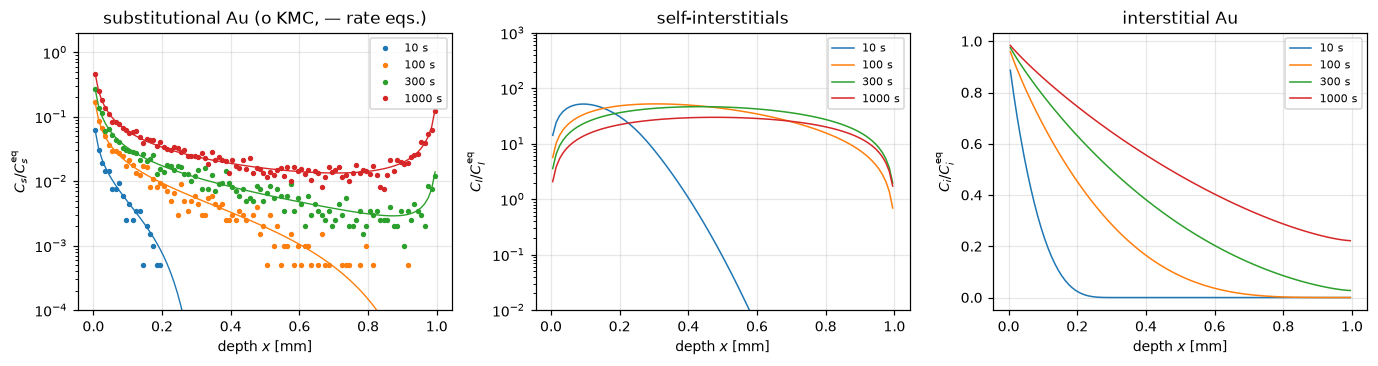

C_s/C_s^eq at 1000 s (rate equations): surface 0.473, minimum 0.0134 at x = 0.70 mm, back surface 0.128
  front 5 cells  : KMC 0.2294   rate equations 0.2307
  middle 5 cells : KMC 0.0134   rate equations 0.0158
  back 5 cells   : KMC 0.0638   rate equations 0.0637
local equilibrium C_i/C_i^eq = (C_s/C_s^eq)(C_I/C_I^eq) at mid-wafer: 0.472 vs 0.472


In [8]:
# deterministic rate equations with the same cells and boundaries, as an independent check
def rhs(t, y):
    ci, cs, cI = y[:M3], y[M3:2 * M3], y[2 * M3:]
    gi = np.concatenate(([CI_EQ], ci, [ci[-1]]))
    gI = np.concatenate(([0.0], cI, [0.0]))
    lap_i = (gi[:-2] - 2 * ci + gi[2:]) / DX3 ** 2
    lap_I = (gI[:-2] - 2 * cI + gI[2:]) / DX3 ** 2
    R = KF * ci - KR * cs * cI / CI_EQ_I
    return np.concatenate((D3 * lap_i - R, R, D3 * lap_I + R))


sol = solve_ivp(rhs, (0, t3[-1]), np.zeros(3 * M3), method="BDF", t_eval=t3,
                rtol=1e-6, atol=1e-14)
xc3 = (np.arange(M3) + 0.5) * DX3 * 1e3

fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.4))
for k, t in enumerate(t3):
    l, = ax[0].semilogy(xc3, np.maximum(ko[k, 1], 1e-5), "o", ms=2.5, label=f"{t:.0f} s")
    ax[0].semilogy(xc3, np.maximum(sol.y[M3:2 * M3, k], 1e-5), "-", lw=0.9, color=l.get_color())
    ax[1].semilogy(xc3, np.maximum(sol.y[2 * M3:, k] / CI_EQ_I, 1e-3), "-", lw=1.0,
                   color=l.get_color(), label=f"{t:.0f} s")
    ax[2].plot(xc3, sol.y[:M3, k] / CI_EQ, "-", lw=1.0, color=l.get_color(), label=f"{t:.0f} s")
ax[0].set(xlabel="depth $x$ [mm]", ylabel=r"$C_s / C_s^{\rm eq}$", ylim=(1e-4, 2),
          title=r"substitutional Au (o KMC, — rate eqs.)")
ax[1].set(xlabel="depth $x$ [mm]", ylabel=r"$C_I / C_I^{\rm eq}$", ylim=(1e-2, 1e3),
          title="self-interstitials")
ax[2].set(xlabel="depth $x$ [mm]", ylabel=r"$C_i / C_i^{\rm eq}$", title="interstitial Au")
for a in ax:
    a.legend(fontsize=7)
plt.show()

cs_end = sol.y[M3:2 * M3, -1]
print("C_s/C_s^eq at 1000 s (rate equations): surface %.3f, minimum %.4f at x = %.2f mm, "
      "back surface %.3f" % (cs_end[0], cs_end.min(), xc3[cs_end.argmin()], cs_end[-1]))
for name, sl in [("front 5 cells", slice(0, 5)), ("middle 5 cells", slice(48, 53)),
                 ("back 5 cells", slice(-5, None))]:
    print(f"  {name:15s}: KMC {ko[-1,1,sl].mean():.4f}   rate equations {cs_end[sl].mean():.4f}")
print(f"local equilibrium C_i/C_i^eq = (C_s/C_s^eq)(C_I/C_I^eq) at mid-wafer: "
      f"{sol.y[M3//2,-1]/CI_EQ:.3f} vs {cs_end[M3//2]*sol.y[2*M3+M3//2,-1]/CI_EQ_I:.3f}")

**The weird profiles.** After 1000 s the substitutional gold is *not* an erfc-like profile decaying
from the coated surface. It is U-shaped: high at the gold-coated surface, two orders of magnitude lower
in the middle of the wafer, and rising again towards the **uncoated back surface**, where there is no
gold source at all. The explanation is the kick-out mechanism:

1. Au$_i$ is fast ($D = 10^{-9}$ m²/s, $\sqrt{Dt} \approx 1$ mm in 1000 s) but rare, and it can only
   become substitutional by kicking out a Si atom, which creates a self-interstitial.
2. In a dislocation-free crystal the only sinks for I are the surfaces. In the bulk the I created by
   the first kick-outs accumulate to hundreds of times $C_I^{\rm eq}$, the reverse reaction then
   balances the forward one, and local equilibrium $C_i/C_i^{\rm eq} = (C_s/C_s^{\rm eq})(C_I/C_I^{\rm eq})$
   is established (checked in the last line above): with $C_I \gg C_I^{\rm eq}$ the alloy can hold
   only very little Au$_s$. Gold incorporation is limited by how fast the I can diffuse out.
3. Near both surfaces the I escape quickly, $C_I$ stays close to equilibrium, and gold is
   incorporated rapidly. Au$_i$ reaches the back surface through the whole wafer, so Au$_s$ builds up
   there as well — the gold arrives from the front, but it is *incorporated* where the
   self-interstitials can leave.
4. The I profile has the inverse shape, a broad maximum in the middle, and the Au$_i$ concentration
   decreases only slowly through the wafer.

The surface concentration itself rises only slowly towards the solubility, as observed by Lerch and
Stolwijk. The KMC and the rate equations agree within the statistical noise of the KMC.